# Binôme B — Convolutional Autoencoder for road anomaly detection

**CRISP-DM phases:** Data Preparation (AE-specific) → Modeling → Evaluation.
**Team:** Khaled & Adrian (FR document, Binôme B).

**Idea** (DL notes, Cap. 9.11): train an autoencoder **only on normal data**. It learns to reconstruct normal road scenes well. On an unexpected object it reconstructs badly, so the **reconstruction error is high** there. The per-pixel error map is the anomaly score, and a threshold turns it into a mask.

**Decisions inherited from `01_Data_Understanding.ipynb`**

| EDA finding | What this notebook does |
|---|---|
| No image is anomaly-free, but about 5,500 64x64 patches of the **train** images are (§9) | Train on anomaly-free **patches** of the train split only |
| Working resolution `IMG_SIZE = (352, 640)` (§7) | Same size; the AE is fully convolutional, so it runs on full images at test time |
| Objects almost never in the top of the image; no perspective trend (§6) | Augmentation: horizontal flip only |
| 9.85 % anomaly pixels, so accuracy is meaningless (§12.1) | No accuracy anywhere |
| Score maps: AuPRC is the main metric, AUROC is reported with its chance level (§12.3) | AuPRC, AUROC and AUPRO (FPR cap 0.3) on validation and test |
| Several obstacles per image, many of them small (§12.4, §12.7) | Object recall / precision, split into small and large objects |
| Speckle under 16 px at full resolution (§12.5) | Objects smaller than 4 px at 352x640 are ignored when counting objects |
| Only 9 test images (§12.8) | Test means come with 95 % bootstrap intervals |
| Model, threshold and XAI choices use train/validation only | Test was consulted during development; saved results are exploratory |

## 0. Setup

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from scipy import ndimage
from sklearn.metrics import average_precision_score, roc_auc_score

import tensorflow as tf
import keras
from keras import layers

from roadanomaly import data_pipeline as dp
from roadanomaly import metrics
from roadanomaly.gpu import setup_gpu

import warnings
warnings.filterwarnings('ignore')

: 

In [2]:
# Constants: values come from notebook 01 (sections 6, 7 and 12)
SEED = 1337
IMG_SIZE = (352, 640)          # working resolution (height, width)
MIN_OBJECT_PX = 4              # speckle threshold at 352x640 (16 px at 1280x720)
SMALL_OBJECT_PX = round(1000 * (352 / 720) ** 2)   # "small" object = < 1000 px at full resolution
FPR_LIMIT = 0.3                # integration limit of AUPRO (always reported with the score)

# Preprocessing
PATCH = 64                     # patch size for training the autoencoder
STRIDE = 32                    # patches overlap by half
MASK_MARGIN = 4                # px added around each obstacle before selecting normal patches

# Training
ENCODER_FILTERS = [32, 64, 128, 256]   # 4 stride-2 levels: 64 -> 32 -> 16 -> 8 -> 4
CODE_CHANNELS = 2              # bottleneck 4x4x2 = 32 values for a 64x64x3 = 12,288-value patch (384x)
LEARNING_RATE = 1e-3
BATCH_SIZE = 64
MAX_EPOCHS = 150
PATIENCE = 8                   # early-stopping patience, on the validation loss

# Post-processing (both chosen on validation)
SIGMA_CANDIDATES = [0, 2, 4, 8, 16]               # Gaussian smoothing of the error map
THRESHOLD_QUANTILES = np.linspace(0.50, 0.995, 60) # candidate thresholds = quantiles of val scores

FIG_DIR = dp.REPO_ROOT / "reports" / "figures"
MODEL_DIR = dp.REPO_ROOT / "models"          # git-ignored
MODEL_DIR.mkdir(exist_ok=True)

# Reproducibility: same seed for Python, NumPy and TensorFlow, and deterministic GPU ops
# (without this, two runs on the same GPU stop at different epochs and give different scores)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| small object limit at 352x640:", SMALL_OBJECT_PX, "px")

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | small object limit at 352x640: 239 px


## 1. Load the shared split
Same split, resolution and mask convention as the other bin?mes. Train and validation are loaded here; the test split appears later only for the already-recorded evaluation. The test set has been consulted during an earlier iteration, so treat its current metrics as exploratory and do not use them for further choices.


In [ ]:
# Load train and validation images (float32 in [0, 1]) and binary masks (1 = anomaly)
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)

# Verify the shared preprocessing contract before extracting patches.
for split_name, frames, images, masks in [
    ("train", train_frames, x_train, y_train),
    ("val", val_frames, x_val, y_val),
]:
    assert len(frames) == len(images) == len(masks), f"{split_name}: frame/image/mask counts differ"
    assert images.shape[1:] == (*IMG_SIZE, 3), f"{split_name}: unexpected image shape {images.shape}"
    assert masks.shape[1:] == (*IMG_SIZE, 1), f"{split_name}: unexpected mask shape {masks.shape}"
    assert images.dtype == np.float32 and masks.dtype == np.float32
    assert np.isfinite(images).all() and np.isfinite(masks).all()
    assert images.min() >= 0.0 and images.max() <= 1.0, f"{split_name}: images must be normalized to [0, 1]"
    assert set(np.unique(masks)).issubset({0.0, 1.0}), f"{split_name}: masks must be binary"
assert set(map(str, train_frames)).isdisjoint(map(str, val_frames)), "Train and validation contain overlapping frames"
print("Preprocessing checks passed: resized RGB float32 images in [0, 1], binary masks, disjoint frames.")
print("x_train:", x_train.shape, "| y_train:", y_train.shape)
print("x_val  :", x_val.shape, "| y_val  :", y_val.shape)


## 2. Data preprocessing for the autoencoder
The AE must see **normal** content only. Every train image contains an obstacle, so each image is cut into overlapping 64x64 patches and only the patches with **no anomaly pixel** are kept.

Annotation borders are not perfectly tight around the objects, so the anomaly mask is first **dilated by a few pixels**. Patches that touch the border of an obstacle are then also discarded.

The validation images go through the same steps. Their normal patches give the validation loss used for early stopping (DL notes, Cap. 5.4: never use the test set for that).

In [ ]:
def extract_normal_patches(images, masks, patch=PATCH, stride=STRIDE, margin=MASK_MARGIN):
    """Cut images into overlapping patches and keep those with no anomaly pixel.

    The anomaly mask is dilated by `margin` px first, so that patches touching the
    (loosely annotated) border of an obstacle are discarded too.
    """
    normal, total = [], 0
    for image, mask in zip(images, masks):
        unsafe = ndimage.binary_dilation(mask[..., 0] > 0, iterations=margin)
        for y in range(0, image.shape[0] - patch + 1, stride):
            for x in range(0, image.shape[1] - patch + 1, stride):
                total += 1
                if not unsafe[y:y + patch, x:x + patch].any():
                    normal.append(image[y:y + patch, x:x + patch])
    return np.stack(normal), total

# Normal patches for training and for early stopping
p_train, n_train_candidates = extract_normal_patches(x_train, y_train)
p_val, n_val_candidates = extract_normal_patches(x_val, y_val)
for split_name, patches in [("train", p_train), ("val", p_val)]:
    assert patches.ndim == 4 and patches.shape[1:] == (PATCH, PATCH, 3)
    assert len(patches) > 0, f"{split_name}: no normal patches were extracted"
    assert patches.dtype == np.float32 and np.isfinite(patches).all()
    assert patches.min() >= 0.0 and patches.max() <= 1.0
print(f"train: kept {len(p_train)} normal patches of {n_train_candidates} -> {p_train.shape}")
print(f"val  : kept {len(p_val)} normal patches of {n_val_candidates} -> {p_val.shape}")


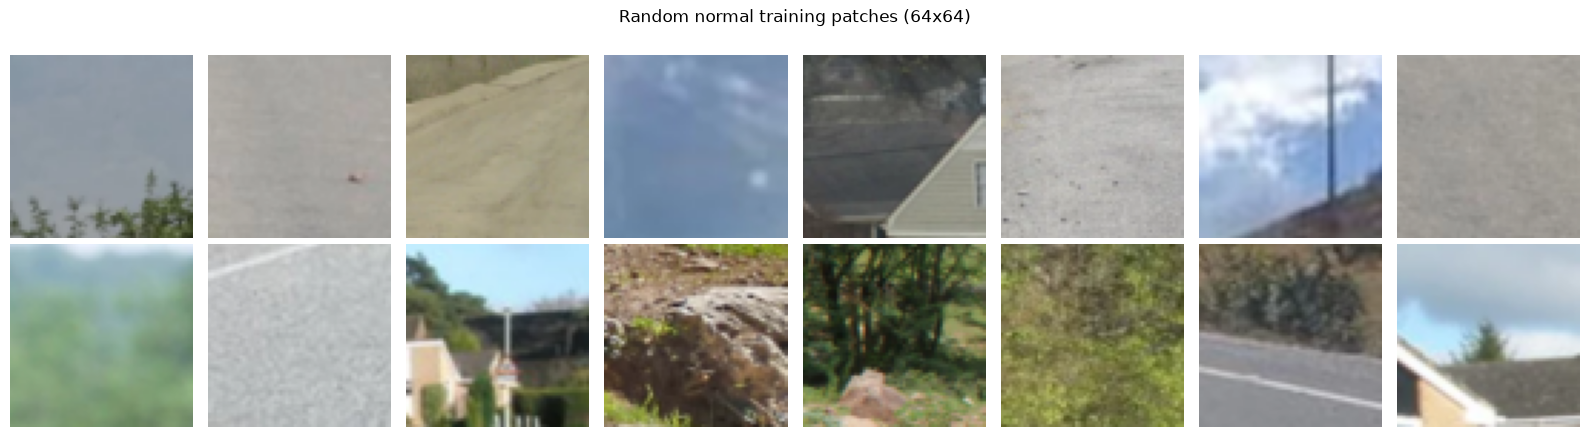

In [5]:
# Show some of the normal patches the autoencoder will learn from
fig, ax = plt.subplots(2, 8, figsize=(16, 4.5), tight_layout=True)
for a, i in zip(ax.flat, np.random.default_rng(SEED).choice(len(p_train), 16, replace=False)):
    a.imshow(p_train[i])
    a.axis("off")
plt.suptitle("Random normal training patches (64x64)")
plt.show()

In [6]:
# tf.data pipelines: shuffled + augmented for training, plain for validation
def augment_patch(patch):
    """Random horizontal flip only (EDA, section 6: scenes are never upside down).
    Returns (input, target): an autoencoder reconstructs its own input."""
    patch = tf.image.random_flip_left_right(patch)
    return patch, patch

train_ds = (tf.data.Dataset.from_tensor_slices(p_train)
            .shuffle(len(p_train), seed=SEED)
            .map(augment_patch, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((p_val, p_val)).batch(BATCH_SIZE)


I0000 00:00:1793393790.416560 3904725 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [ ]:
# Visual check: the training transform is a horizontal flip; validation stays unchanged.
original_patch = tf.convert_to_tensor(p_train[0])
augmented_input, augmented_target = augment_patch(original_patch)
assert tuple(augmented_input.shape) == (PATCH, PATCH, 3)
assert np.array_equal(augmented_input.numpy(), augmented_target.numpy())
assert np.array_equal(p_val[0], val_ds.unbatch().take(1).get_single_element()[0].numpy())
fig, ax = plt.subplots(1, 2, figsize=(6, 3), tight_layout=True)
ax[0].imshow(original_patch.numpy()); ax[0].set_title("Normal train patch")
ax[1].imshow(augmented_input.numpy()); ax[1].set_title("Train patch after random flip")
for a in ax: a.axis("off")
plt.show()
print("Augmentation check passed: paired input/target match; validation is unaugmented.")


## 3. Model: convolutional autoencoder
Design choices, following the DL notes (Cap. 9):
- **Encoder:** convolutions with `stride=2` halve the size four times (64 → 32 → 16 → 8 → 4), as in Lab 7. Hidden layers use **ReLU**; Lab 7 left them linear, which is a bug. The only linear layer is the 2-channel code (see 3.1).
- **Bottleneck:** 4x4x2 = 32 values for a 64x64x3 = 12,288-value input. The AE is strongly **undercomplete** (384x compression), so it can only reproduce the *typical* appearance of a road scene, not every local detail. Section 3.1 explains why the bottleneck is this narrow.
- **Decoder:** `Conv2DTranspose` with `stride=2` doubles the size back to 64x64. A **sigmoid** output keeps pixels in [0, 1].
- **No skip connections:** that would turn it into a U-Net, and the information would bypass the bottleneck (Cap. 10.3).
- **Loss:** MSE between the input and its reconstruction. The anomaly score is the same quantity computed per pixel.
- **Fully convolutional:** trained on 64x64 patches, it can reconstruct a whole 352x640 image (both sides are divisible by 16).

In [7]:
def get_model(filters=ENCODER_FILTERS, code_channels=CODE_CHANNELS, channels=3):
    """Convolutional autoencoder: stride-2 conv blocks down, a narrow code, mirrored transposed blocks up."""
    inputs = keras.Input(shape=(None, None, channels))   # any size divisible by 2 ** len(filters)

    # Encoder: each stride-2 convolution halves height and width (64 -> 32 -> 16 -> 8 -> 4)
    x = inputs
    for n_filters in filters:
        x = layers.Conv2D(n_filters, 3, strides=2, padding="same", activation="relu")(x)

    # Bottleneck (the code): very few channels force a strongly compressed representation.
    # Linear on purpose: with only 2 channels, a ReLU unit that "dies" (always 0) would
    # delete half of the code (dying ReLU, DL notes Cap. 4.3.1; see the seed check in 3.1)
    code = layers.Conv2D(code_channels, 3, padding="same", activation=None, name="code")(x)

    # Decoder: mirror of the encoder, each transposed convolution doubles the size back
    x = code
    for n_filters in reversed(filters):
        x = layers.Conv2DTranspose(n_filters, 3, strides=2, padding="same", activation="relu")(x)
    outputs = layers.Conv2D(channels, 3, padding="same", activation="sigmoid")(x)   # pixels in [0, 1]

    return keras.Model(inputs, outputs, name="conv_autoencoder")

autoencoder = get_model()
autoencoder.summary()

Model: "conv_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, None, None, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, None, None, 64) │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Conv2D)                   │ (None, None, None, 2)  │         4,610 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, None, None,     │         4,864 │
│ (Conv2DTranspose)               │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, None, None,     │       295,040 │
│ (Conv2DTranspose)               │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, None, None, 64) │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, None, None, 32) │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, None, None, 3)  │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 786,053 (3.00 MB)

 Trainable params: 786,053 (3.00 MB)

 Non-trainable params: 0 (0.00 B)

### 3.1 Why such a narrow bottleneck (model selection on validation only)
The first version used 3 levels and 16 code channels (12x compression). It reconstructed the obstacles **as well as the road**: boulders, animals and cones came out almost perfect, and the error only lit up on high-contrast textures (stripes, facades, foliage). This is the failure mode of a too-powerful AE described in the DL notes (Cap. 9.6): it "learns to reconstruct almost anything".

The bottleneck was then narrowed, and the error map was standardised per image (section 5). Every variant was compared on the **validation split only** (9 images, chance AuPRC = 0.091), with the same training recipe:

| Encoder levels | Code channels | Compression | Val AuPRC (raw / per-image z) | Val AUROC (raw / per-image z) |
|---|---|---|---|---|
| 3 | 16 | 12x | 0.081 / 0.096 | 0.42 / 0.49 |
| 3 | 4 | 48x | 0.091 / 0.133 | 0.45 / 0.61 |
| 3 | 1 | 192x | 0.089 / 0.101 | 0.46 / 0.55 |
| 4 | 8 | 96x | 0.101 / 0.142 | 0.48 / 0.62 |
| **4** | **2** | **384x** | **0.113 / 0.151** | **0.54 / 0.67** |

(Gaussian smoothing sigma = 8 for all rows.) The search was stopped there on purpose: with 9 validation images, comparing many more variants would start to fit the validation set itself.

**Seed check: ReLU vs linear code.** With only 2 code channels, a ReLU bottleneck can collapse if a unit dies (DL notes, Cap. 4.3.1). Each version was trained with 3 seeds (validation only, sigma = 16):

| Code activation | Val MSE (mean ± std) | Val AuPRC | Val AUROC | Note |
|---|---|---|---|---|
| ReLU | 0.0084 ± 0.0019 | 0.137 ± 0.016 | 0.655 ± 0.030 | one seed collapsed (val MSE 0.011) |
| **Linear** | **0.0069 ± 0.0000** | **0.150 ± 0.002** | **0.680 ± 0.004** | stable |

The linear code is kept. Its results barely depend on the seed, so the single-seed numbers below are representative.

**Transparency note:** the initial and current model versions were both evaluated on the test split during development. The current test results are retained below for transparency, but repeated exposure makes them exploratory rather than an independent final estimate. Model changes were based on validation; do not make further choices from test.

## 4. Training

In [8]:
# Adam + MSE; early stopping and checkpoint watch the validation loss (never the test set)
autoencoder.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse")

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(str(MODEL_DIR / "B_autoencoder.keras"), monitor="val_loss", save_best_only=True),
]
history = autoencoder.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=0)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Stopped after {len(history.history['loss'])} epochs, best epoch {best_epoch}, "
      f"best val MSE {min(history.history['val_loss']):.5f}")

2026-10-30 21:56:32.833503: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92700


Stopped after 46 epochs, best epoch 38, best val MSE 0.00692


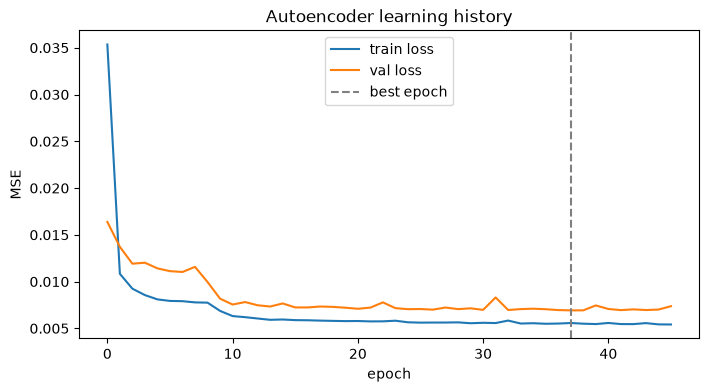

In [9]:
# Learning curves: training vs validation loss (the gap shows over-fitting, DL notes Cap. 5)
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label="best epoch")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Autoencoder learning history")
plt.legend()
plt.savefig(FIG_DIR / "B_01_learning_curves.png", dpi=80)
plt.show()

## 5. From reconstruction to an anomaly score map
The AE reconstructs the **whole image** at once. The anomaly score of a pixel is its squared reconstruction error, averaged over the 3 colour channels.

Two post-processing steps turn the raw error into a usable score:
1. **Gaussian smoothing.** Raw per-pixel errors are noisy (texture, edges); smoothing turns them into region-like scores. The strength `sigma` is chosen on **validation** with the main metric (AuPRC).
2. **Per-image standardisation** (z-score). Texture-rich images (foliage, buildings) have a high error *everywhere*, so one global threshold would flag those whole images. Standardising each error map turns the score into "how unusual is this pixel **compared to the rest of its own image**". Limitation: this assumes that an image is mostly normal. On an image with no obstacle at all, its highest-error pixels would still stand out.

In [10]:
def reconstruction_error_maps(model, images):
    """Reconstruct full images; return (reconstructions, per-pixel squared error averaged over RGB)."""
    reconstructions = model.predict(images, batch_size=4, verbose=0)
    return reconstructions, ((images - reconstructions) ** 2).mean(axis=-1)

def smooth(error_maps, sigma):
    """Gaussian smoothing of each error map (sigma = 0 means no smoothing)."""
    if sigma == 0:
        return error_maps
    return np.stack([ndimage.gaussian_filter(m, sigma) for m in error_maps])

def standardise_per_image(maps):
    """z-score of each map: how unusual a pixel is compared with the rest of its own image."""
    return np.stack([(m - m.mean()) / m.std() for m in maps])

def anomaly_scores(error_maps, sigma):
    """Full post-processing: smoothing, then per-image standardisation."""
    return standardise_per_image(smooth(error_maps, sigma))

recon_val, err_val = reconstruction_error_maps(autoencoder, x_val)
print("reconstructions:", recon_val.shape, "| error maps:", err_val.shape)

2026-10-30 21:57:39.252161: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


reconstructions: (9, 352, 640, 3) | error maps: (9, 352, 640)


In [11]:
# Choose the smoothing strength on validation with AuPRC (pixel level)
gt_val = y_val[..., 0].astype(bool)
rows = []
for sigma in SIGMA_CANDIDATES:
    s = anomaly_scores(err_val, sigma)
    rows.append({"sigma": sigma,
                 "AuPRC": average_precision_score(gt_val.ravel(), s.ravel()),
                 "AUROC": roc_auc_score(gt_val.ravel(), s.ravel())})
sigma_df = pd.DataFrame(rows).round(4)
SIGMA = int(sigma_df.loc[sigma_df["AuPRC"].idxmax(), "sigma"])
print(sigma_df.to_string(index=False))
print("\nChosen sigma:", SIGMA, f"| AuPRC chance level on val = prevalence = {gt_val.mean():.4f}")
score_val = anomaly_scores(err_val, SIGMA)

 sigma  AuPRC  AUROC
     0 0.1360 0.6368
     2 0.1413 0.6387
     4 0.1445 0.6475
     8 0.1457 0.6604
    16 0.1477 0.6765

Chosen sigma: 16 | AuPRC chance level on val = prevalence = 0.0907


## 6. Threshold-free evaluation on validation
These metrics judge the **score map itself**, before any threshold:
- **AuPRC:** main metric. Its chance level is the anomaly prevalence.
- **AUROC:** reported as FR asks, but its chance level is 0.5 whatever the imbalance, so it looks better than it is.
- **AUPRO** up to FPR = 0.3: every obstacle weighs the same, whatever its size.

In [12]:
def threshold_free_scores(gt, scores):
    """Pixel AuPRC / AUROC and region-level AUPRO, each with the chance level to compare against."""
    return {"AuPRC": average_precision_score(gt.ravel(), scores.ravel()),
            "AuPRC chance": gt.mean(),
            "AUROC": roc_auc_score(gt.ravel(), scores.ravel()),
            "AUROC chance": 0.5,
            f"AUPRO@{FPR_LIMIT}": metrics.aupro(list(gt), list(scores), MIN_OBJECT_PX, fpr_limit=FPR_LIMIT),
            "AUPRO chance": FPR_LIMIT / 2}

val_free = threshold_free_scores(gt_val, score_val)
print({k: round(v, 4) for k, v in val_free.items()})

{'AuPRC': 0.1477, 'AuPRC chance': np.float64(0.0907), 'AUROC': 0.6765, 'AUROC chance': 0.5, 'AUPRO@0.3': 0.5061, 'AUPRO chance': 0.15}


## 7. Threshold: from score map to anomaly mask
Following the protocol (notebook 01, §12), the threshold is the one that maximises the **per-image mean F1 on validation**. Candidate thresholds are high quantiles of the validation scores. After thresholding, predicted blobs smaller than `MIN_OBJECT_PX` are removed (the same speckle rule as the ground truth).

Chosen threshold: 0.62787 (val per-image mean F1 = 0.2342)


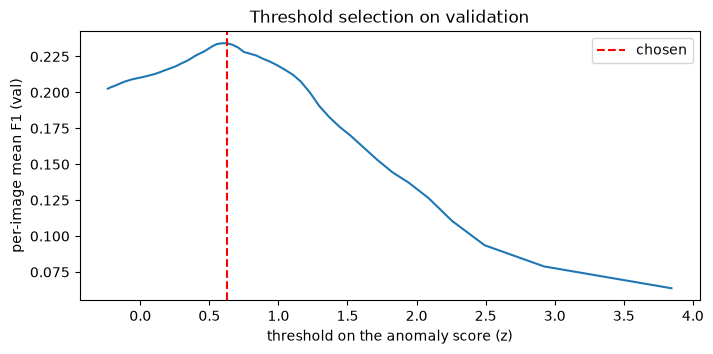

In [13]:
def to_masks(scores, threshold):
    """Threshold the score maps, then drop blobs smaller than the speckle limit."""
    return np.stack([metrics.remove_small_components(s >= threshold, MIN_OBJECT_PX) for s in scores])

def mean_f1(gt, scores, threshold):
    """Per-image mean F1 of the masks obtained with this threshold."""
    return metrics.evaluate_masks(list(gt), list(to_masks(scores, threshold)))["per_image_mean"]["f1"]

candidates = np.quantile(score_val, THRESHOLD_QUANTILES)
f1_per_threshold = [mean_f1(gt_val, score_val, t) for t in candidates]
THRESHOLD = float(candidates[int(np.argmax(f1_per_threshold))])
print(f"Chosen threshold: {THRESHOLD:.5f} (val per-image mean F1 = {max(f1_per_threshold):.4f})")

plt.figure(figsize=(8, 3.5))
plt.plot(candidates, f1_per_threshold)
plt.axvline(THRESHOLD, color="red", linestyle="--", label="chosen")
plt.xlabel("threshold on the anomaly score (z)")
plt.ylabel("per-image mean F1 (val)")
plt.title("Threshold selection on validation")
plt.legend()
plt.show()

In [ ]:
# Save the exact run and validation-calibration settings (no test metrics enter this file).
import json
import platform

run_config = {
    "seed": SEED,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__,
    "python_version": platform.python_version(),
    "device": {"gpu_name": GPU_NAME, "physical_devices": [d.name for d in tf.config.list_physical_devices()]},
    "split": {"train_frames": len(train_frames), "validation_frames": len(val_frames)},
    "preprocessing": {
        "image_size_height_width": list(IMG_SIZE),
        "image_channels": "RGB",
        "image_resize": "bilinear (shared data pipeline)",
        "image_dtype_range": "float32 [0, 1]",
        "mask_resize": "nearest-neighbour (shared data pipeline)",
        "mask_labels": {"normal": 0, "anomaly": 1},
        "patch_size": PATCH,
        "patch_stride": STRIDE,
        "mask_dilation_margin_px": MASK_MARGIN,
        "training_augmentation": "random horizontal flip only",
        "validation_augmentation": "none",
        "normal_patches": {"train": len(p_train), "validation": len(p_val)},
    },
    "model": {
        "architecture": "fully convolutional convolutional autoencoder",
        "encoder_filters": ENCODER_FILTERS,
        "code_channels": CODE_CHANNELS,
        "code_activation": "linear",
        "output_activation": "sigmoid",
        "loss": "mean squared error",
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "maximum_epochs": MAX_EPOCHS,
        "early_stopping_patience": PATIENCE,
        "epochs_ran": len(history.history["loss"]),
        "best_epoch": best_epoch,
        "best_validation_mse": float(min(history.history["val_loss"])),
    },
    "anomaly_score": {
        "pixel_error": "mean squared RGB reconstruction error",
        "gaussian_sigma_selected_on_validation": SIGMA,
        "per_image_z_score": True,
        "threshold_selected_on_validation_for_mean_f1": THRESHOLD,
        "validation_auprc": float(average_precision_score(gt_val.ravel(), score_val.ravel())),
    },
    "test_split_policy": "Previously consulted during an earlier iteration; excluded from all model, threshold, and XAI choices.",
}
run_config_path = MODEL_DIR / "B_autoencoder_run.json"
run_config_path.write_text(json.dumps(run_config, indent=2), encoding="utf-8")
print("Run configuration saved to:", run_config_path)


## 8. Thresholded evaluation on validation

In [14]:
def full_report(gt, scores, threshold):
    """All protocol metrics for one split: pixel (per image + aggregated), objects, size, confusion."""
    masks = to_masks(scores, threshold)
    pix = metrics.evaluate_masks(list(gt), list(masks))
    obj = pd.DataFrame([metrics.object_scores(g, m, MIN_OBJECT_PX) for g, m in zip(gt, masks)])
    size = pd.DataFrame([metrics.object_recall_by_size(g, m, MIN_OBJECT_PX, SMALL_OBJECT_PX) for g, m in zip(gt, masks)]).sum()
    tp, fp, fn, tn = metrics.confusion_counts(gt, masks)
    return {"masks": masks, "pixel": pix, "objects": obj, "size": size, "confusion": (tp, fp, fn, tn)}

def print_report(report):
    """Readable summary of full_report()."""
    print("Pixel metrics, per-image mean :", {k: round(v, 4) for k, v in report["pixel"]["per_image_mean"].items()})
    print("Pixel metrics, aggregated     :", {k: round(v, 4) for k, v in report["pixel"]["aggregated"].items()})
    o = report["objects"]
    print(f"Objects: recall {o['detected'].sum()}/{o['gt_objects'].sum()} = {o['detected'].sum() / o['gt_objects'].sum():.3f} | "
          f"false alarms {o['false_alarms'].sum()} of {o['pred_objects'].sum()} predicted blobs | "
          f"mean object F1 per image {o['object_f1'].mean():.3f}")
    s = report["size"]
    print(f"Object recall by size: small {s['small_detected']}/{s['small_total']} | large {s['large_detected']}/{s['large_total']}")
    tp, fp, fn, tn = report["confusion"]
    print(f"Pixel confusion matrix: TP {tp}  FP {fp}  FN {fn}  TN {tn}")

val_report = full_report(gt_val, score_val, THRESHOLD)
print_report(val_report)

Pixel metrics, per-image mean : {'precision': 0.1687, 'recall': 0.5688, 'f1': 0.2342, 'iou': 0.1378, 'dice': 0.2342}
Pixel metrics, aggregated     : {'precision': 0.1619, 'recall': 0.3833, 'f1': 0.2276, 'iou': 0.1284, 'dice': 0.2276}
Objects: recall 25/36 = 0.694 | false alarms 52 of 65 predicted blobs | mean object F1 per image 0.112
Object recall by size: small 9/12 | large 16/24
Pixel confusion matrix: TP 70491  FP 364911  FN 113409  TN 1478709


In [15]:
# Reference: what trivial predictors score on the same validation images (notebook 01, section 11)
for name, pred in [("all background", np.zeros_like(gt_val)), ("all anomaly", np.ones_like(gt_val))]:
    print(f"{name:15s}", {k: round(v, 3) for k, v in metrics.evaluate_masks(list(gt_val), list(pred))["per_image_mean"].items()})

all background  {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'iou': 0.0, 'dice': 0.0}
all anomaly     {'precision': 0.091, 'recall': 1.0, 'f1': 0.159, 'iou': 0.091, 'dice': 0.159}


**Reading the validation results**
- **Threshold-free:** AuPRC is **0.148**, about 1.6x its chance level (0.091), and AUROC is **0.68**. The score map carries real but weak information about where the obstacles are.
- **Thresholded:** per-image mean F1 is **0.234**, above the trivial "all anomaly" baseline (0.159). Recall (0.57) is much higher than precision (0.17): the masks find most obstacle pixels but spread over a lot of background.
- **Objects:** 25 of 36 obstacles are covered at ≥ 50 % (small 9/12, large 16/24), but **52 of the 65 predicted blobs are false alarms**. False alarms, not misses, are this model's main weakness.

## 9. Optional VGG19 perceptual-loss experiment (validation only)

The full report proposes a VGG19 feature-space reconstruction loss for Binome B. This is an **additional experiment**, not a replacement for the existing MSE baseline. It compares three variants: the already-trained MSE baseline, a fresh MAE-only autoencoder, and a fresh autoencoder trained with `MAE + 0.1 * perceptual loss`. The VGG19 ImageNet weights are **frozen**; only the autoencoder is trained. This is not fine-tuning VGG19 and does not make the autoencoder RoadAnomaly-pretrained.

The perceptual term averages the relative mean absolute feature error at VGG19 `block1_conv2` through `block5_conv2` (the report's `conv1_2` to `conv5_2` shorthand). VGG inputs use the Keras VGG19 preprocessing function. The coefficient is fixed in advance rather than searched on this small validation set. Each variant selects its smoothing and threshold on validation with the same protocol; no test data enters this comparison. The MAE-only ablation helps distinguish the effect of the feature term from changing MSE to MAE. ImageNet weight licensing/terms must be checked before redistributing a model.

The experiment is opt-in because it downloads ImageNet weights and trains two additional autoencoders. Set `RUN_VGG19_EXPERIMENT = True` below after the baseline cells have completed. VGG19 itself remains frozen; no VGG fine-tuning is planned for this project.


In [ ]:
# Optional ablation: MSE baseline vs. MAE vs. MAE + frozen VGG19 perceptual loss.
RUN_VGG19_EXPERIMENT = False
VGG_PERCEPTUAL_WEIGHT = 0.1
VGG_FEATURE_LAYERS = ["block1_conv2", "block2_conv2", "block3_conv2", "block4_conv2", "block5_conv2"]

class PerceptualAutoencoder(keras.Model):
    def __init__(self, reconstruction_model, feature_model=None, perceptual_weight=0.0):
        super().__init__()
        self.reconstruction_model = reconstruction_model
        self.feature_model = feature_model
        self.perceptual_weight = perceptual_weight
        self.total_tracker = keras.metrics.Mean(name="loss")
        self.pixel_tracker = keras.metrics.Mean(name="mae")
        self.perceptual_tracker = keras.metrics.Mean(name="perceptual_loss")

    @property
    def metrics(self):
        return [self.total_tracker, self.pixel_tracker, self.perceptual_tracker]

    def call(self, inputs, training=False):
        return self.reconstruction_model(inputs, training=training)

    def _compute_loss_components(self, inputs, targets, training):
        reconstruction = self.reconstruction_model(inputs, training=training)
        pixel_loss = tf.reduce_mean(tf.abs(targets - reconstruction))
        perceptual_loss = tf.constant(0.0, dtype=pixel_loss.dtype)
        if self.feature_model is not None:
            target_vgg = keras.applications.vgg19.preprocess_input(targets * 255.0)
            reconstruction_vgg = keras.applications.vgg19.preprocess_input(reconstruction * 255.0)
            target_features = self.feature_model(target_vgg, training=False)
            reconstruction_features = self.feature_model(reconstruction_vgg, training=False)
            layer_losses = []
            for target_feature, reconstructed_feature in zip(target_features, reconstruction_features):
                numerator = tf.reduce_mean(tf.abs(target_feature - reconstructed_feature))
                denominator = tf.reduce_mean(tf.abs(target_feature)) + tf.keras.backend.epsilon()
                layer_losses.append(numerator / denominator)
            perceptual_loss = tf.reduce_mean(tf.stack(layer_losses))
        total_loss = pixel_loss + self.perceptual_weight * perceptual_loss
        return total_loss, pixel_loss, perceptual_loss

    def train_step(self, data):
        inputs, targets, sample_weight = keras.utils.unpack_x_y_sample_weight(data)
        if sample_weight is not None:
            raise ValueError("Sample weights are not supported in this experiment")
        with tf.GradientTape() as tape:
            total_loss, pixel_loss, perceptual_loss = self._compute_loss_components(inputs, targets, training=True)
        variables = self.reconstruction_model.trainable_variables
        gradients = tape.gradient(total_loss, variables)
        gradient_pairs = [(gradient, variable) for gradient, variable in zip(gradients, variables) if gradient is not None]
        if not gradient_pairs:
            raise RuntimeError("No gradients reached the autoencoder parameters")
        self.optimizer.apply_gradients(gradient_pairs)
        self.total_tracker.update_state(total_loss)
        self.pixel_tracker.update_state(pixel_loss)
        self.perceptual_tracker.update_state(perceptual_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def test_step(self, data):
        inputs, targets, sample_weight = keras.utils.unpack_x_y_sample_weight(data)
        if sample_weight is not None:
            raise ValueError("Sample weights are not supported in this experiment")
        total_loss, pixel_loss, perceptual_loss = self._compute_loss_components(inputs, targets, training=False)
        self.total_tracker.update_state(total_loss)
        self.pixel_tracker.update_state(pixel_loss)
        self.perceptual_tracker.update_state(perceptual_loss)
        return {metric.name: metric.result() for metric in self.metrics}

if RUN_VGG19_EXPERIMENT:
    vgg_backbone = keras.applications.VGG19(
        include_top=False,
        weights="imagenet",
        input_shape=(PATCH, PATCH, 3),
    )
    vgg_backbone.trainable = False
    vgg_feature_model = keras.Model(
        inputs=vgg_backbone.input,
        outputs=[vgg_backbone.get_layer(name).output for name in VGG_FEATURE_LAYERS],
        name="frozen_vgg19_features",
    )
    assert not vgg_feature_model.trainable

    experiment_specs = [
        ("mae", None, 0.0),
        ("mae_vgg19", vgg_feature_model, VGG_PERCEPTUAL_WEIGHT),
    ]
    vgg_experiment_rows = [{
        "variant": "mse_baseline_existing",
        "loss": "MSE",
        "validation_auprc": float(average_precision_score(gt_val.ravel(), score_val.ravel())),
        "validation_mean_f1": float(val_report["pixel"]["per_image_mean"]["f1"]),
        "sigma": int(SIGMA),
        "threshold": float(THRESHOLD),
        "best_epoch": int(best_epoch),
    }]
    vgg_variant_models = {}
    vgg_variant_histories = {}

    for variant_name, feature_model, perceptual_weight in experiment_specs:
        keras.utils.set_random_seed(SEED)
        variant_autoencoder = get_model()
        training_model = PerceptualAutoencoder(
            variant_autoencoder,
            feature_model=feature_model,
            perceptual_weight=perceptual_weight,
        )
        training_model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE))
        variant_history = training_model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=MAX_EPOCHS,
            callbacks=[keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=PATIENCE, restore_best_weights=True
            )],
            verbose=2,
        )
        variant_autoencoder.save(MODEL_DIR / f"B_autoencoder_{variant_name}.keras")
        vgg_variant_models[variant_name] = variant_autoencoder
        vgg_variant_histories[variant_name] = variant_history.history

        variant_reconstruction, variant_error = reconstruction_error_maps(variant_autoencoder, x_val)
        sigma_rows = []
        for candidate_sigma in SIGMA_CANDIDATES:
            candidate_scores = anomaly_scores(variant_error, candidate_sigma)
            sigma_rows.append((
                average_precision_score(gt_val.ravel(), candidate_scores.ravel()),
                candidate_sigma,
                candidate_scores,
            ))
        variant_auprc, variant_sigma, variant_scores = max(sigma_rows, key=lambda row: row[0])
        variant_thresholds = np.quantile(variant_scores, THRESHOLD_QUANTILES)
        variant_f1_values = [mean_f1(gt_val, variant_scores, threshold) for threshold in variant_thresholds]
        variant_threshold = float(variant_thresholds[int(np.argmax(variant_f1_values))])
        variant_report = full_report(gt_val, variant_scores, variant_threshold)
        vgg_experiment_rows.append({
            "variant": variant_name,
            "loss": "MAE" if feature_model is None else f"MAE + {perceptual_weight} x relative VGG19 feature MAE",
            "validation_auprc": float(variant_auprc),
            "validation_mean_f1": float(variant_report["pixel"]["per_image_mean"]["f1"]),
            "sigma": int(variant_sigma),
            "threshold": variant_threshold,
            "best_epoch": int(np.argmin(variant_history.history["val_loss"])) + 1,
            "best_validation_loss": float(min(variant_history.history["val_loss"])),
        })
        if variant_name == "mae_vgg19":
            vgg19_reconstruction_val = variant_reconstruction
            vgg19_error_val = variant_error
            vgg19_score_val = variant_scores
            vgg19_sigma = int(variant_sigma)
            vgg19_threshold = variant_threshold
            vgg19_report_val = variant_report

    vgg_comparison = pd.DataFrame(vgg_experiment_rows)
    print(vgg_comparison.round(4).to_string(index=False))
    comparison_path = MODEL_DIR / "B_vgg19_validation_comparison.json"
    comparison_path.write_text(vgg_comparison.to_json(orient="records", indent=2), encoding="utf-8")
    print("Validation-only comparison saved to:", comparison_path)

    ax = vgg_comparison.set_index("variant")[["validation_auprc", "validation_mean_f1"]].plot(
        kind="bar", figsize=(9, 4), ylim=(0, 1), rot=15
    )
    ax.set_ylabel("validation score")
    ax.set_title("Autoencoder ablation (all calibration on validation)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "B_05_vgg19_perceptual_ablation.png", dpi=100, bbox_inches="tight")
    plt.show()
else:
    print("VGG19 experiment skipped. Set RUN_VGG19_EXPERIMENT = True to download ImageNet weights and train MAE / MAE+VGG19 variants.")


## 10. Explainability diagnostic (validation only)

The anomaly score is a reconstruction error, not a classifier decision. This section therefore asks a narrowly defined question: **which bottleneck locations have positive gradients for the mean raw reconstruction error inside one validation-predicted anomaly region?** A Grad-CAM-style map is upsampled to image resolution and shown beside the input, reconstruction, error, ground truth, and predicted region. Ground truth is displayed only for context; it does not define the explanation target.

Deletion/insertion curves perturb the pixels highlighted by the map and track that same fixed scalar. They are a sanity check, not proof of causal reasoning; image perturbations may be out of distribution, and the bottleneck map is spatially coarse. No test image or test label is used for XAI.


In [ ]:
# Pick a validation image with a predicted anomaly region; if empty, use its top 1% score pixels.
xai_index = int(np.argmax([m.sum() for m in val_report["masks"]]))
xai_image = x_val[xai_index]
xai_reconstruction = recon_val[xai_index]
xai_error_map = err_val[xai_index]
xai_score_map = score_val[xai_index]
xai_region = val_report["masks"][xai_index].astype(bool)
xai_region_source = "validation-predicted mask"
if not xai_region.any():
    xai_region = xai_score_map >= np.quantile(xai_score_map, 0.99)
    xai_region_source = "top 1% of validation score map (empty-mask fallback)"
assert xai_region.any(), "Could not define a non-empty validation attribution region"

xai_model = keras.Model(
    inputs=autoencoder.inputs,
    outputs=[autoencoder.get_layer("code").output, autoencoder.output],
)
xai_input_tensor = tf.convert_to_tensor(xai_image[None, ...], dtype=tf.float32)
xai_region_tensor = tf.convert_to_tensor(xai_region[None, ...], dtype=tf.float32)
with tf.GradientTape() as tape:
    xai_features, xai_reconstruction_tensor = xai_model(xai_input_tensor, training=False)
    tape.watch(xai_features)
    xai_raw_error = tf.reduce_mean(tf.square(xai_input_tensor - xai_reconstruction_tensor), axis=-1)
    xai_target = tf.math.divide_no_nan(
        tf.reduce_sum(xai_raw_error * xai_region_tensor),
        tf.reduce_sum(xai_region_tensor),
    )
xai_gradients = tape.gradient(xai_target, xai_features)
if xai_gradients is None:
    raise RuntimeError("Grad-CAM gradients are unavailable for the autoencoder code layer")
xai_weights = tf.reduce_mean(xai_gradients, axis=(1, 2), keepdims=True)
xai_cam = tf.nn.relu(tf.reduce_sum(xai_weights * xai_features, axis=-1, keepdims=True))
xai_cam = tf.image.resize(xai_cam, IMG_SIZE, method="bilinear")[0, ..., 0]
xai_cam = xai_cam / (tf.reduce_max(xai_cam) + 1e-8)
xai_heatmap = xai_cam.numpy()
assert xai_heatmap.shape == IMG_SIZE and np.isfinite(xai_heatmap).all()
print(f"Validation frame: {val_frames[xai_index]} | target: mean raw RGB MSE in {xai_region_source}")
print(f"Target value: {float(xai_target):.6f} | attribution range: {xai_heatmap.min():.3f}?{xai_heatmap.max():.3f}")

fig, ax = plt.subplots(1, 6, figsize=(20, 4), tight_layout=True)
ax[0].imshow(xai_image); ax[0].set_title("Input")
ax[1].imshow(xai_reconstruction); ax[1].set_title("Reconstruction")
im = ax[2].imshow(xai_error_map, cmap="magma"); ax[2].set_title("Raw reconstruction error")
ax[3].imshow(xai_image); ax[3].imshow(xai_heatmap, cmap="jet", alpha=0.45); ax[3].set_title("Grad-CAM candidate")
ax[4].imshow(xai_region, cmap="gray"); ax[4].set_title("Fixed target region")
ax[5].imshow(y_val[xai_index, ..., 0], cmap="gray"); ax[5].set_title("GT (context only)")
for a in ax: a.axis("off")
fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04)
plt.savefig(FIG_DIR / "B_03_validation_gradcam.png", dpi=100, bbox_inches="tight")
plt.show()


In [ ]:
# Faithfulness sanity check: perturb high-attribution pixels and track the fixed scalar target.
def validation_region_error(image, region):
    image_tensor = tf.convert_to_tensor(image[None, ...], dtype=tf.float32)
    _, reconstruction = xai_model(image_tensor, training=False)
    error = tf.reduce_mean(tf.square(image_tensor - reconstruction), axis=-1)[0]
    region_tensor = tf.convert_to_tensor(region, dtype=tf.float32)
    return float(tf.math.divide_no_nan(tf.reduce_sum(error * region_tensor), tf.reduce_sum(region_tensor)))

fractions = np.linspace(0.0, 1.0, 6)
coordinates = np.argwhere(xai_region)
ranked_coordinates = coordinates[np.argsort(xai_heatmap[xai_region])[::-1]]
neutral_pixel = xai_image.mean(axis=(0, 1))
delete_scores, insert_scores = [], []
for fraction in fractions:
    count = int(round(fraction * len(ranked_coordinates)))
    selected = ranked_coordinates[:count]
    deleted = xai_image.copy()
    inserted = np.broadcast_to(neutral_pixel, xai_image.shape).copy()
    if count:
        deleted[selected[:, 0], selected[:, 1]] = neutral_pixel
        inserted[selected[:, 0], selected[:, 1]] = xai_image[selected[:, 0], selected[:, 1]]
    delete_scores.append(validation_region_error(deleted, xai_region))
    insert_scores.append(validation_region_error(inserted, xai_region))

plt.figure(figsize=(6, 4))
plt.plot(fractions, delete_scores, marker="o", label="Deletion: top-attribution pixels replaced")
plt.plot(fractions, insert_scores, marker="o", label="Insertion: top-attribution pixels restored")
plt.xlabel("Fraction of target-region pixels perturbed")
plt.ylabel("Mean raw reconstruction error in fixed region")
plt.title("Validation-only attribution sanity check")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "B_04_validation_xai_perturbation.png", dpi=100, bbox_inches="tight")
plt.show()
print("Interpret curves descriptively only; they are not a causal explanation or a pass/fail test.")


## 11. Historical evaluation on the test split (already consulted)
The saved results below are retained for transparency; the test set was already consulted during an earlier model iteration, so this is **not an untouched final holdout**. No model, post-processing, or XAI choices should be made from these results. The 95% intervals summarize variation across the 9 test images.


In [16]:
# Load the frozen test split and compute the score maps with the frozen settings
test_frames, x_test, y_test = dp.load_split("test", IMG_SIZE)
gt_test = y_test[..., 0].astype(bool)
recon_test, err_test = reconstruction_error_maps(autoencoder, x_test)
score_test = anomaly_scores(err_test, SIGMA)

test_free = threshold_free_scores(gt_test, score_test)
print("Threshold-free:", {k: round(v, 4) for k, v in test_free.items()})
print()
test_report = full_report(gt_test, score_test, THRESHOLD)
print_report(test_report)

2026-10-30 21:57:47.013268: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Threshold-free: {'AuPRC': 0.1772, 'AuPRC chance': np.float64(0.0859), 'AUROC': 0.6635, 'AUROC chance': 0.5, 'AUPRO@0.3': 0.5256, 'AUPRO chance': 0.15}

Pixel metrics, per-image mean : {'precision': 0.1781, 'recall': 0.5054, 'f1': 0.2454, 'iou': 0.1577, 'dice': 0.2454}
Pixel metrics, aggregated     : {'precision': 0.1657, 'recall': 0.439, 'f1': 0.2406, 'iou': 0.1368, 'dice': 0.2406}
Objects: recall 16/22 = 0.727 | false alarms 36 of 42 predicted blobs | mean object F1 per image 0.082
Object recall by size: small 0/0 | large 16/22
Pixel confusion matrix: TP 76499  FP 385060  FN 97741  TN 1468220


In [17]:
# 95 % bootstrap intervals over the 9 test images
ci_rows = []
for key in ["precision", "recall", "f1", "iou", "dice"]:
    mean, low, high = metrics.bootstrap_ci([s[key] for s in test_report["pixel"]["per_image"]])
    ci_rows.append({"metric": key, "mean": mean, "95% CI low": low, "95% CI high": high})
mean, low, high = metrics.bootstrap_ci(test_report["objects"]["object_f1"])
ci_rows.append({"metric": "object F1", "mean": mean, "95% CI low": low, "95% CI high": high})
ci_df = pd.DataFrame(ci_rows).round(3)
ci_df

,metric,mean,95% CI low,95% CI high
0,precision,0.178,0.082,0.288
1,recall,0.505,0.247,0.753
2,f1,0.245,0.117,0.388
3,iou,0.158,0.070,0.262
4,dice,0.245,0.117,0.388
5,object F1,0.082,0.000,0.190


In [18]:
# Per-image results on test: they show where the model works and where it fails
per_image = pd.DataFrame(test_report["pixel"]["per_image"]).round(3)
per_image.insert(0, "frame", [f[:35] for f in test_frames])
per_image["anomaly %"] = (100 * gt_test.mean(axis=(1, 2))).round(1)
per_image["objects"] = test_report["objects"]["gt_objects"].values
per_image["detected"] = test_report["objects"]["detected"].values
per_image["false alarms"] = test_report["objects"]["false_alarms"].values
per_image

,frame,precision,recall,f1,iou,dice,anomaly %,objects,detected,false alarms
0,animals14_Dekemhare_Road,0.065,0.128,0.086,0.045,0.086,10.0,2,0,3
1,animals17_E6_near_Kvaenangen,0.073,0.992,0.136,0.073,0.136,1.6,1,1,1
2,animals20_Marcassin_Conchiglio,0.007,0.053,0.013,0.006,0.013,4.3,1,0,3
3,animals21_On_The_Road_to_Gondar_Eth,0.369,0.598,0.456,0.296,0.456,15.2,2,2,8
4,animals29_Zebra_Crossing_Abbey_Road,0.429,0.999,0.601,0.429,0.601,7.0,2,2,1
5,cones06_VnA_traffic_cones,0.174,0.891,0.291,0.170,0.291,5.0,6,6,5
6,obstacles09_boulder3,0.000,0.000,0.000,0.000,0.000,5.1,1,0,3
7,obstacles10_boulder4,0.109,0.154,0.128,0.068,0.128,19.1,3,1,5
8,vehicle02_Broadmoor_Cones_Skidloade,0.378,0.733,0.498,0.332,0.498,10.0,4,4,7


## 12. Visual analysis: successes, false positives, false negatives
Each row shows image | ground truth | reconstruction | error map | predicted mask. Rows are ordered from the best to the worst test F1.

**Reading the error map (XAI note from FR):** the error map shows **where the AE reconstructs badly**. It is a detection map, **not a causal explanation**: high error can come from an obstacle, but also from any texture the AE did not learn (signs, shadows, sky).

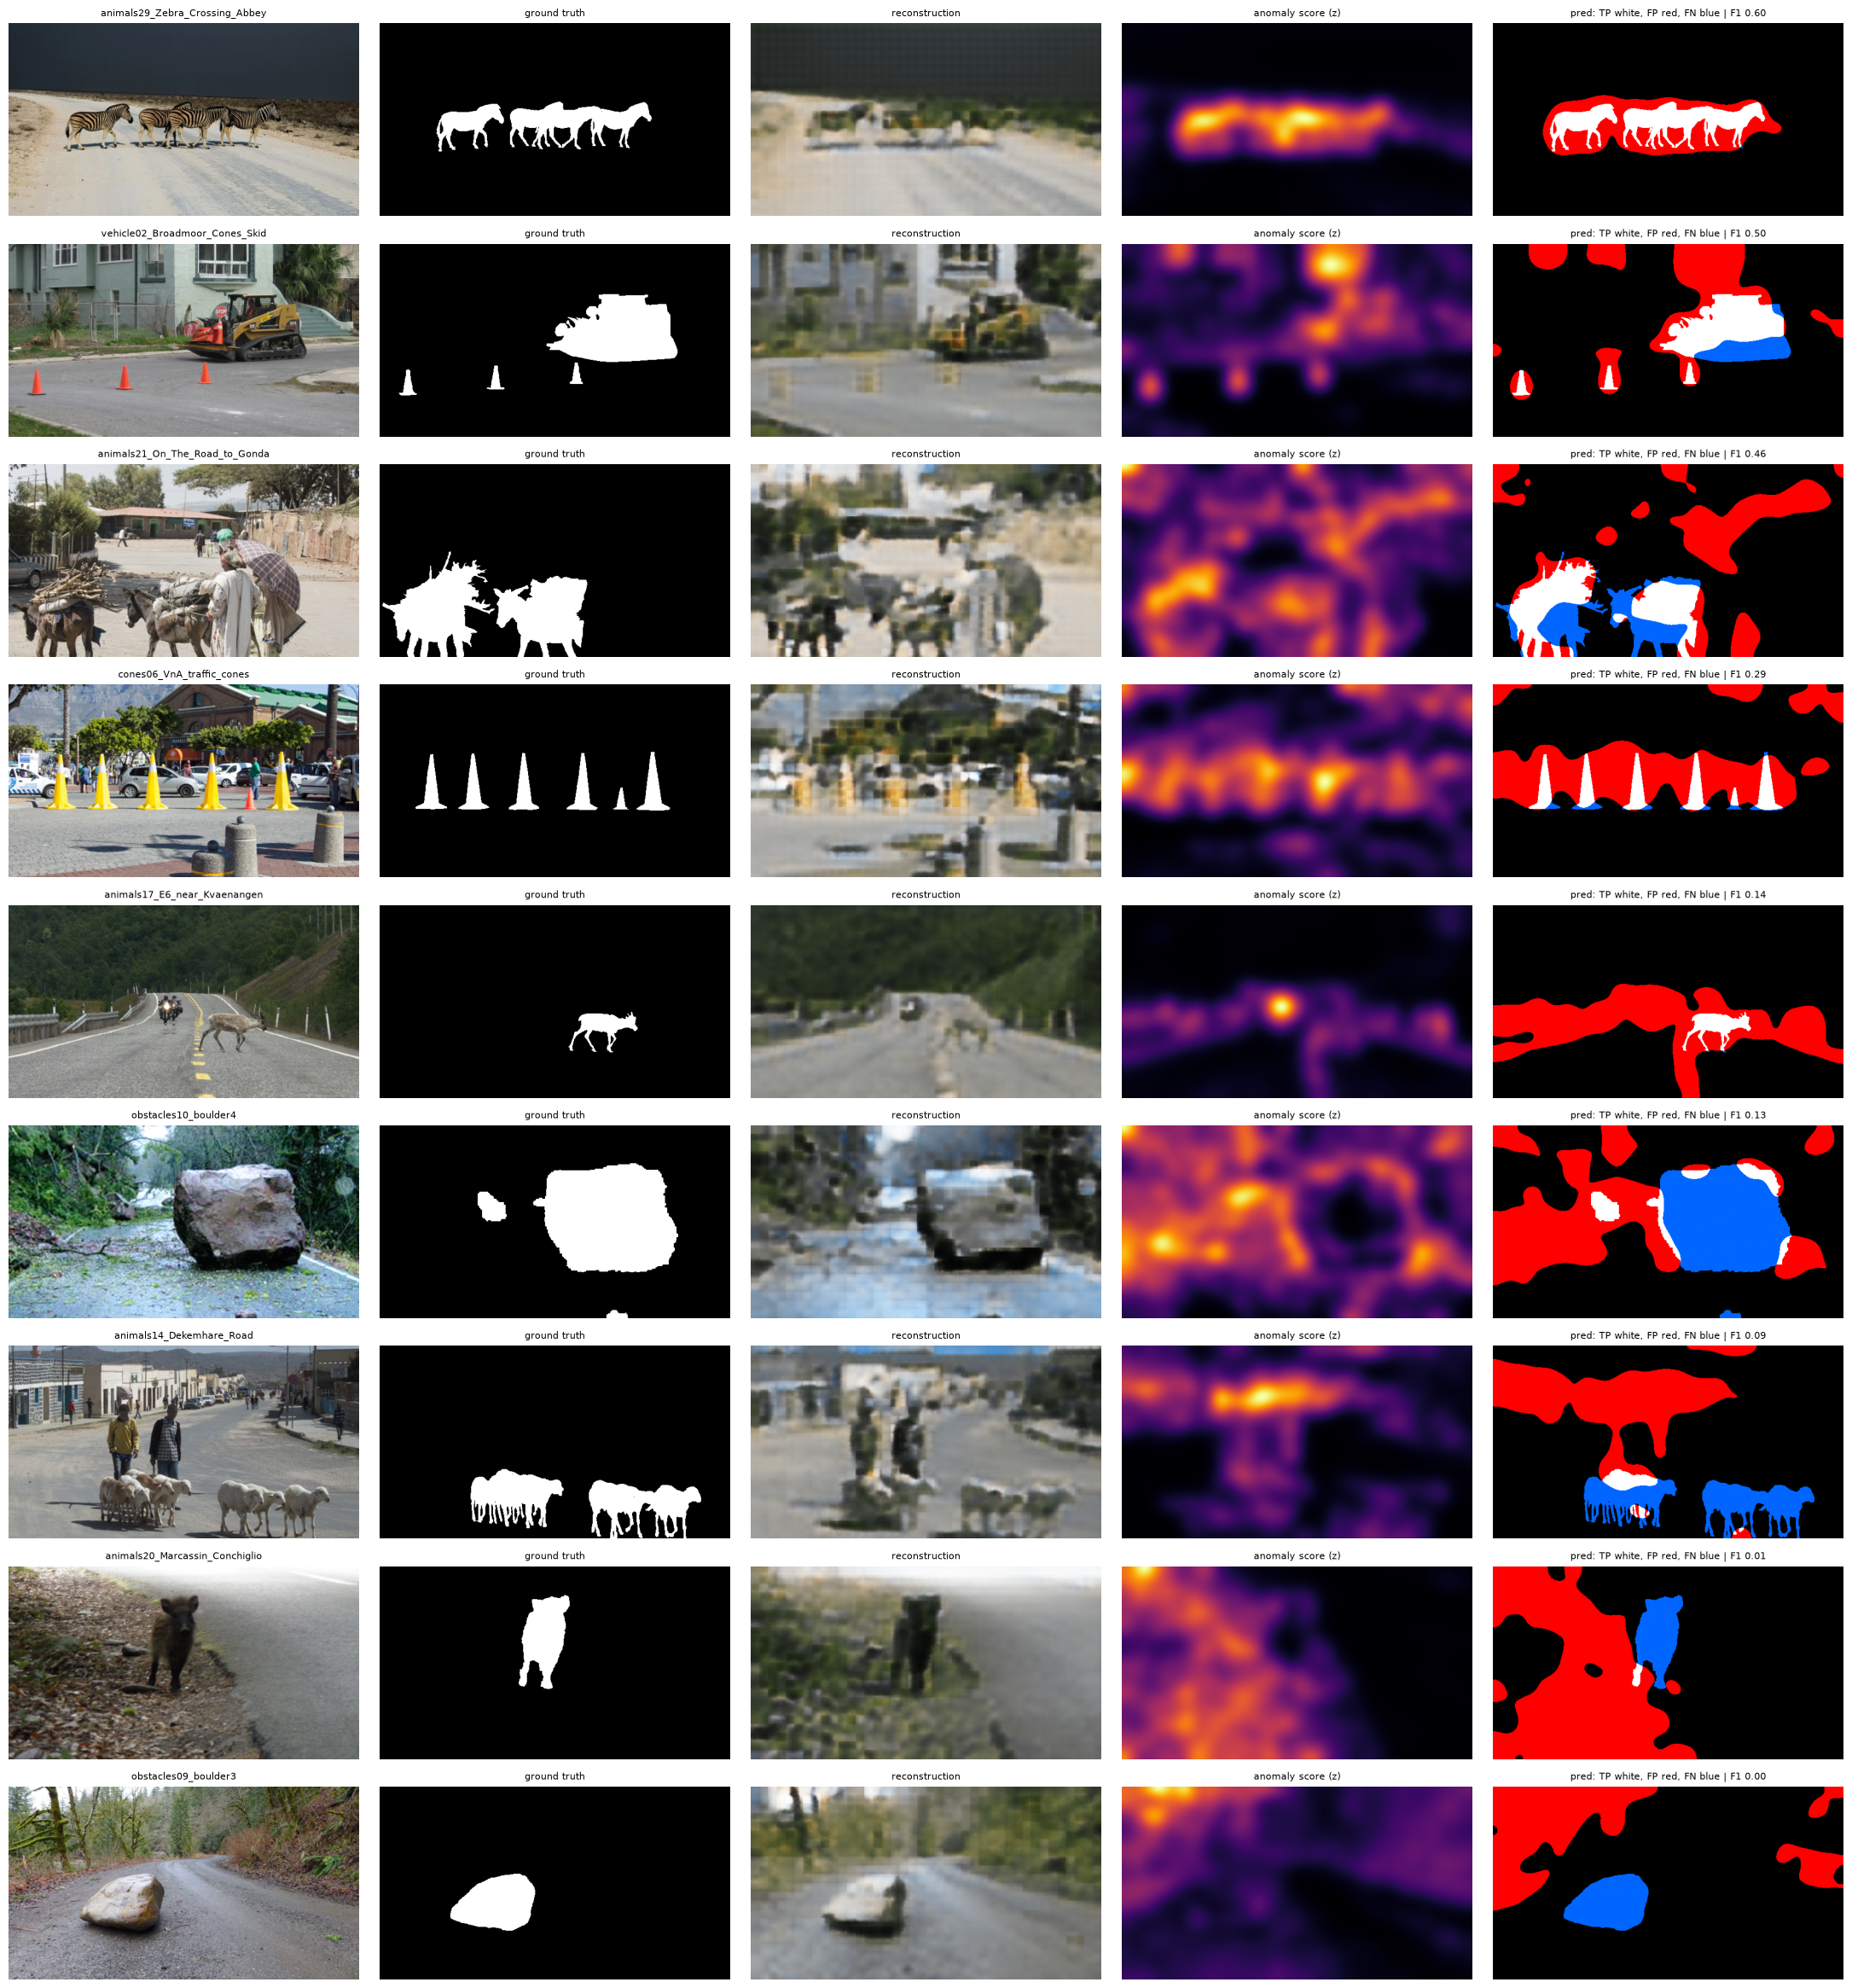

In [19]:
# Show every test image, best to worst F1, with an error-map overlay of FP (red) / FN (blue)
order = np.argsort([-s["f1"] for s in test_report["pixel"]["per_image"]])
fig, ax = plt.subplots(len(order), 5, figsize=(22, 2.6 * len(order)), tight_layout=True)
for row, i in enumerate(order):
    pred = test_report["masks"][i].astype(bool)
    errors = np.zeros(gt_test[i].shape + (3,))
    errors[pred & gt_test[i]] = (1, 1, 1)      # true positives: white
    errors[pred & ~gt_test[i]] = (1, 0, 0)     # false positives: red
    errors[~pred & gt_test[i]] = (0, 0.4, 1)   # false negatives: blue
    panels = [(x_test[i], test_frames[i][:30]), (gt_test[i], "ground truth"),
              (recon_test[i], "reconstruction"), (score_test[i], "anomaly score (z)"),
              (errors, f"pred: TP white, FP red, FN blue | F1 {test_report['pixel']['per_image'][i]['f1']:.2f}")]
    for col, (panel, title) in enumerate(panels):
        ax[row, col].imshow(panel, cmap="inferno" if col == 3 else ("gray" if panel.ndim == 2 else None))
        ax[row, col].set_title(title, fontsize=8)
        ax[row, col].axis("off")
plt.savefig(FIG_DIR / "B_02_test_examples.png", dpi=60)
plt.show()

## 13. Results and critical analysis

**Summary (validation drove the recorded choices; the test split was consulted during iteration and is not an untouched holdout)**

| Metric | Validation | Test | Test 95 % CI | Chance / trivial reference |
|---|---|---|---|---|
| AuPRC (main) | 0.148 | 0.177 | — | prevalence: 0.091 (val), 0.086 (test) |
| AUROC | 0.677 | 0.664 | — | 0.5 |
| AUPRO @ FPR 0.3 | 0.506 | 0.526 | — | 0.15 |
| Pixel F1 = Dice, per-image mean | 0.234 | 0.245 | 0.117 – 0.388 | "all anomaly": 0.159 (val) |
| Pixel IoU, per-image mean | 0.138 | 0.158 | 0.070 – 0.262 | "all anomaly": 0.091 (val) |
| Precision / Recall, per-image mean | 0.169 / 0.569 | 0.178 / 0.505 | — | — |
| Object recall (≥ 50 % covered) | 25/36 | 16/22 | — | — |
| Object false alarms / predicted blobs | 52/65 | 36/42 | — | — |

Validation and the recorded test results are numerically similar, but the test split was consulted during model iteration; treat this agreement as descriptive, not as independent evidence of generalisation. The test split contains no small object (section 11: small 0/0), so the small-object recall can only be judged on validation (9/12).

**What works.** Obstacles whose **colour or contrast differs from a typical road scene** get a high error: the zebras (F1 0.60), the skid-loader and cones (0.50), the traffic cones (0.29, all 6 covered), and the donkeys (0.46).

**What fails, and why.** The AE has no notion of *object*. It only knows *typical local appearance*:
- **False negatives:** obstacles with ordinary colours and textures, such as the grey boulders on a grey road (`obstacles09_boulder3`: F1 0.00) or the brown boar on brown leaf litter (`animals20`: 0.01), are reconstructed well, so their error stays low.
- **False positives:** rich background textures such as foliage, leaf litter, building facades and sky gradients are reconstructed badly, so they score as high as real obstacles. This is the main source of the 36 false alarms on test.
- Pixel reconstruction error measures *"unusual appearance"*, not *"unexpected object on the road"*. That gap is the core limitation of a pixel-space autoencoder on varied, real-world internet photos.

**Limitations to keep in mind**
1. **Small evaluation sets.** With 9 test images the F1 interval is wide (0.12 – 0.39). Differences with the other binômes' models are meaningful only when the intervals do not overlap.
2. **Per-image standardisation** assumes most of an image is normal. On an image with no obstacle at all, its highest-error pixels would still be flagged (every RoadAnomaly image contains an obstacle, so this case is not tested here).
3. **Normal data comes from the same scenes.** The AE learns "normal" from background patches of images that also contain obstacles. A larger set of truly obstacle-free roads would give a better model of normality; per FR it needs an explicit authorisation.
4. **Smoothing.** The chosen `sigma = 16` is the largest value tried. Heavy smoothing makes region-like blobs, which helps the object recall (≥ 50 % coverage) but blurs the boundaries.
5. **Transparency.** Both the earlier and current model versions were evaluated on the test split during development. The current test scores are therefore exploratory, not a final unbiased estimate. Do not make additional choices from them; a new authorised holdout or external dataset is needed for an independent final estimate.

**XAI note (FR, section 5).** The error map remains a **detection map**, not an explanation. The validation-only Grad-CAM above targets a defined scalar (mean raw reconstruction error in a predicted region); deletion/insertion is a limited sanity check. Neither establishes causal reasoning or explains an obstacle decision, because the autoencoder does not classify obstacles.

## 14. Possible next steps (not done here)
- **Feature-space error:** compare deep features of a pretrained encoder instead of raw pixels (a perceptual error, as in Ohgushi et al.). This targets the texture false alarms directly.
- **A structural error such as SSIM** instead of MSE, which is less sensitive to fine texture.
- **More normal data** (obstacle-free road datasets), only with the authorisation required by FR, and kept away from the test split.
- **Joint comparison** with binômes A and C on the same frozen test split, using the same protocol tables.